# 2D synthesis: turbulence images

This tutorial synthesises a batch of 10 periodic images of 256 × 256 whose statistics have the
mean and the variance of 10 images of a 2D turbulence simulation, STL-Dev's 2D example
(`data/test/Turb_6.npy` of the [STL-Dev](https://github.com/STL-Proj/STL-Dev) repository; set
`TURB` to its path). It uses `stl-synth2d` with the ensemble loss (scattering covariance, power
spectrum and Minkowski functionals, batch mean and variance) and a coarse-to-fine start:
synthesis at 64², then 128², each level started from the previous one with details drawn
conditionally on the coarse image.

Run time: about 6 minutes on one Tesla T4.

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "Cargo.toml").exists():          # the repository root, from docs/tutorials
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "examples"))
sys.path.insert(0, str(ROOT / "python" / "stl_ensemble"))
BIN = Path(os.environ.get("STL_BIN", ROOT / "target" / "release"))
WORK = Path(os.environ.get("STL_WORK", ROOT / "docs" / "tutorials" / "out")); WORK.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "plasma"})

def run(*args):
    """Runs a command-line tool, prints its last lines and its wall-clock time."""
    t0 = time.time()
    p = subprocess.run([str(a) for a in args], capture_output=True, text=True)
    if p.returncode:
        raise RuntimeError(p.stderr[-2000:])
    print(p.stdout.strip()[-600:], f"\n[{time.time() - t0:.1f} s]")

In [2]:
get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")   # images: JPEG keeps the notebook small
TURB = Path(os.environ.get("TURB", ROOT.parent / "STL-Dev" / "data" / "test" / "Turb_6.npy"))
target = np.load(TURB)
print(TURB.name, target.shape, target.dtype, "- the first 10 images are the targets")

Turb_6.npy (20, 256, 256) float64 - the first 10 images are the targets


## 1. Synthesis

`--c2f 64,128`: pixel L-BFGS at 64² (from white noise, with a warm start on STL-Dev's loss), then
at 128², then at 256² for `--niter` iterations; the details added at each step are drawn from the
targets' details in bins of the coarse value and gradient.

In [3]:
run(BIN / "stl-synth2d", "--target", TURB, "--ntarget", 10, "--nbatch", 10, "--mode", "ensemble",
    "--c2f", "64,128", "--warm", 100, "--niter", 300, "--gpu", "--out", WORK / "turb")
rep = json.load(open(WORK / "turb.json"))
print(f"{rep['evaluations']} evaluations at 256², {rep['seconds_per_evaluation']:.3f} s each; total {rep['seconds']:.0f} s")

{"evaluations":336,"loss_first":9.852283245926898,"loss_last":0.3951187660932191,"peak_device_bytes":725352448,"peak_rss_bytes":1081733120,"seconds_per_evaluation":0.5881460434166667} 
[307.6 s]
336 evaluations at 256², 0.588 s each; total 198 s


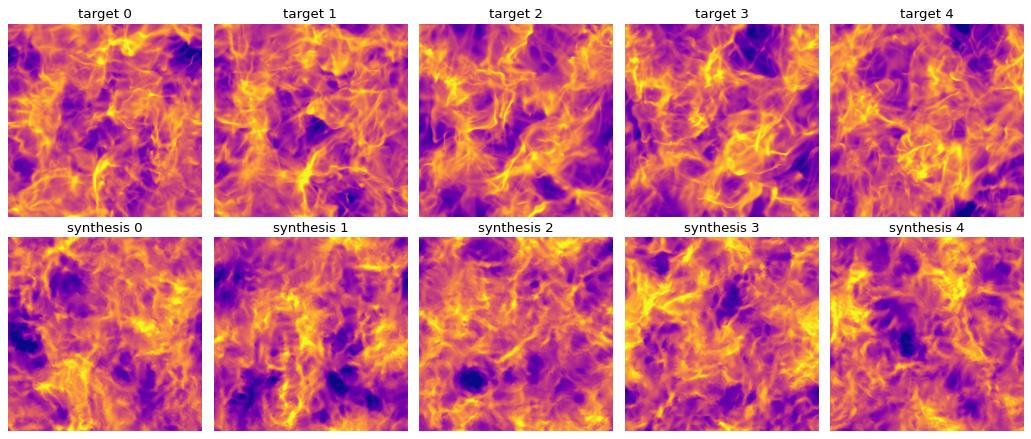

In [4]:
maps = np.load(WORK / "turb_maps.npy")[:, 0]; tgt = np.load(WORK / "turb_target.npy")[:, 0]
lo, hi = np.percentile(tgt, [0.5, 99.5])
fig, ax = plt.subplots(2, 5, figsize=(13, 5.6))
for i in range(5):
    ax[0, i].imshow(tgt[i], vmin=lo, vmax=hi); ax[0, i].set_title(f"target {i}")
    ax[1, i].imshow(maps[i], vmin=lo, vmax=hi); ax[1, i].set_title(f"synthesis {i}")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Checks

The statistics of the batch (`turb_features_*.npy`, in the plan's order, with the family of each
column in the report) against the targets' mean and scatter, the pixel distribution and the
isotropic power spectrum.

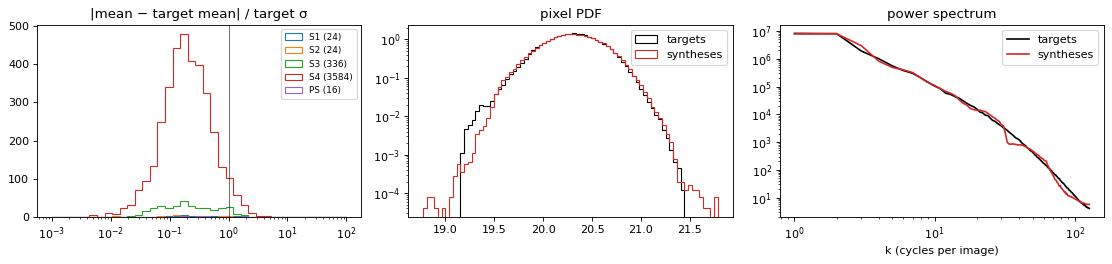

In [5]:
fam = np.array(rep["families"])
feat = {k: np.load(WORK / f"turb_features_{k}.npy") for k in ("target", "init", "final")}
feat = {k: v[..., 0] + 1j * v[..., 1] for k, v in feat.items()}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for f in ("S1", "S2", "S3", "S4", "PS"):
    sel = fam == f
    t = feat["target"][:, sel]; tm, ts = t.mean(0), np.abs(t.std(0, ddof=1))
    pull = np.abs(feat["final"][:, sel].mean(0) - tm) / np.where(ts > 0, ts, np.inf)
    ax[0].hist(np.clip(pull, 1e-3, 1e2), bins=np.logspace(-3, 2, 40), histtype="step", label=f"{f} ({sel.sum()})")
ax[0].set_xscale("log"); ax[0].axvline(1, color="k", lw=0.5); ax[0].legend(fontsize=8)
ax[0].set_title("|mean − target mean| / target σ")
bins = np.linspace(min(tgt.min(), maps.min()), max(tgt.max(), maps.max()), 80)
ax[1].hist(tgt.ravel(), bins, density=True, histtype="step", color="k", label="targets")
ax[1].hist(maps.ravel(), bins, density=True, histtype="step", color="C3", label="syntheses")
ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("pixel PDF")
def iso_ps(a):
    p = np.abs(np.fft.fft2(a - a.mean(axis=(-2, -1), keepdims=True))) ** 2
    k = np.hypot(*np.meshgrid(np.fft.fftfreq(a.shape[-1]), np.fft.fftfreq(a.shape[-2]))) * a.shape[-1]
    kb = np.arange(1, a.shape[-1] // 2)
    return kb, np.array([p[..., (k >= b - 0.5) & (k < b + 0.5)].mean() for b in kb])
for a, c, n in ((tgt, "k", "targets"), (maps, "C3", "syntheses")):
    kb, ps = iso_ps(a); ax[2].loglog(kb, ps, c, label=n)
ax[2].set_xlabel("k (cycles per image)"); ax[2].legend(); ax[2].set_title("power spectrum")
plt.tight_layout(); plt.show()

The batch mean of nearly every coefficient lies within one standard deviation of the targets'
mean, and the pixel distribution and the power spectrum follow the targets'. The dip of the
spectrum around `k = 32` is the Nyquist frequency of the 64² level: the Fourier upsampling of the
coarse-to-fine start drops the Nyquist modes of the smaller grid, and the 256² iterations have
not fully restored them.

More: the options of `stl-synth2d` ({doc}`../user-guide/stl-synth2d`), the benchmarks against
STL-Dev ({doc}`../planar_2d`) and the coarse-to-fine study ({doc}`../lagrangian_synthesis`,
section 6.4).